In [1]:
import cartopy.crs as ccrs
import cartopy.feature as cf
projection = ccrs.Mercator()
crs = ccrs.PlateCarree()

import matplotlib.colors as mcolors

from seasonal_burst.exhaustive_search import exhaustive_search
from seasonal_burst.spatial_search import process_grid
from utils.connected_components import connected_components_bursts
from utils.post_process import merge_bursts


import copy
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap, BoundaryNorm
import seaborn as sns
from IPython.display import HTML
import matplotlib.animation as animation
import warnings, os

import utils_notebook as ub
#import src.steps as steps
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  
    "font.serif": ["Latin Modern Roman"],
})
plt.rcParams['font.size'] = 16

In [2]:
threshold = 3
grid_data_path="../../Data/SST/medi_1960_2021_processed_focused.nc"
parameter="sst"
n_jobs = 6
minimum_length = 1
maximum_length = 90
absolute_threshold = True
animate = False
export = True
filename_html="example_grid"
print("\033[1m"+"Parameters: "+ "\033[0m")
print(f" - threshold = {threshold}")
print(f" - grid_data_path = \"{grid_data_path}\"")
print(f" - parameter = {parameter}")
print(f" - n_jobs = {n_jobs}")
print(f" - animate = {animate}")
print(f" - export = {export}")
print(f" - filename_html = \"{filename_html}\"")

Parameters: 
 - threshold = 3
 - grid_data_path = "../../Data/SST/medi_1960_2021_processed_focused.nc"
 - parameter = sst
 - n_jobs = 6
 - animate = False
 - export = True
 - filename_html = "example_grid"


In [3]:
ds = xr.open_dataset(grid_data_path)[parameter]
time = ds.time
ts_date = pd.DatetimeIndex(time.values)
len_year = 365
n_year = len(ds.time) // len_year
lat = ds.lat.size
lon = ds.lon.size
lon_min = ds.lon.min().values
lon_max = ds.lon.max().values
lat_min = ds.lat.min().values
lat_max = ds.lat.max().values
values = ds.values.astype(np.float64)
first_year = ts_date[0].year
last_year = ts_date[-1].year
years = range(first_year, last_year+1)

In [4]:
%%time
parameter="sst"
grid = ds
values = grid[0,:,:].values
n, lat, lon = grid.shape
valid_coordinates = [(i,j) for j in range(lon) for i in range(lat) if not np.isnan(values[i, j])]

grid_burst =  process_grid(
    grid,
    valid_coordinates,
    threshold,
    n_year,
    len_year,
    minimum_length,
    maximum_length,
    exhaustive_search,
    n_jobs)

CPU times: user 33.8 s, sys: 3.05 s, total: 36.8 s
Wall time: 43.6 s


### Number of burst (after merging) per series

In [5]:
values = ds.values.astype(np.float64)

grid_count, grid_count_hot, grid_count_cold, grid_count_days_hot, grid_count_days_cold, coords = ub.compute_grid_counts(grid_burst, lat, lon, values)

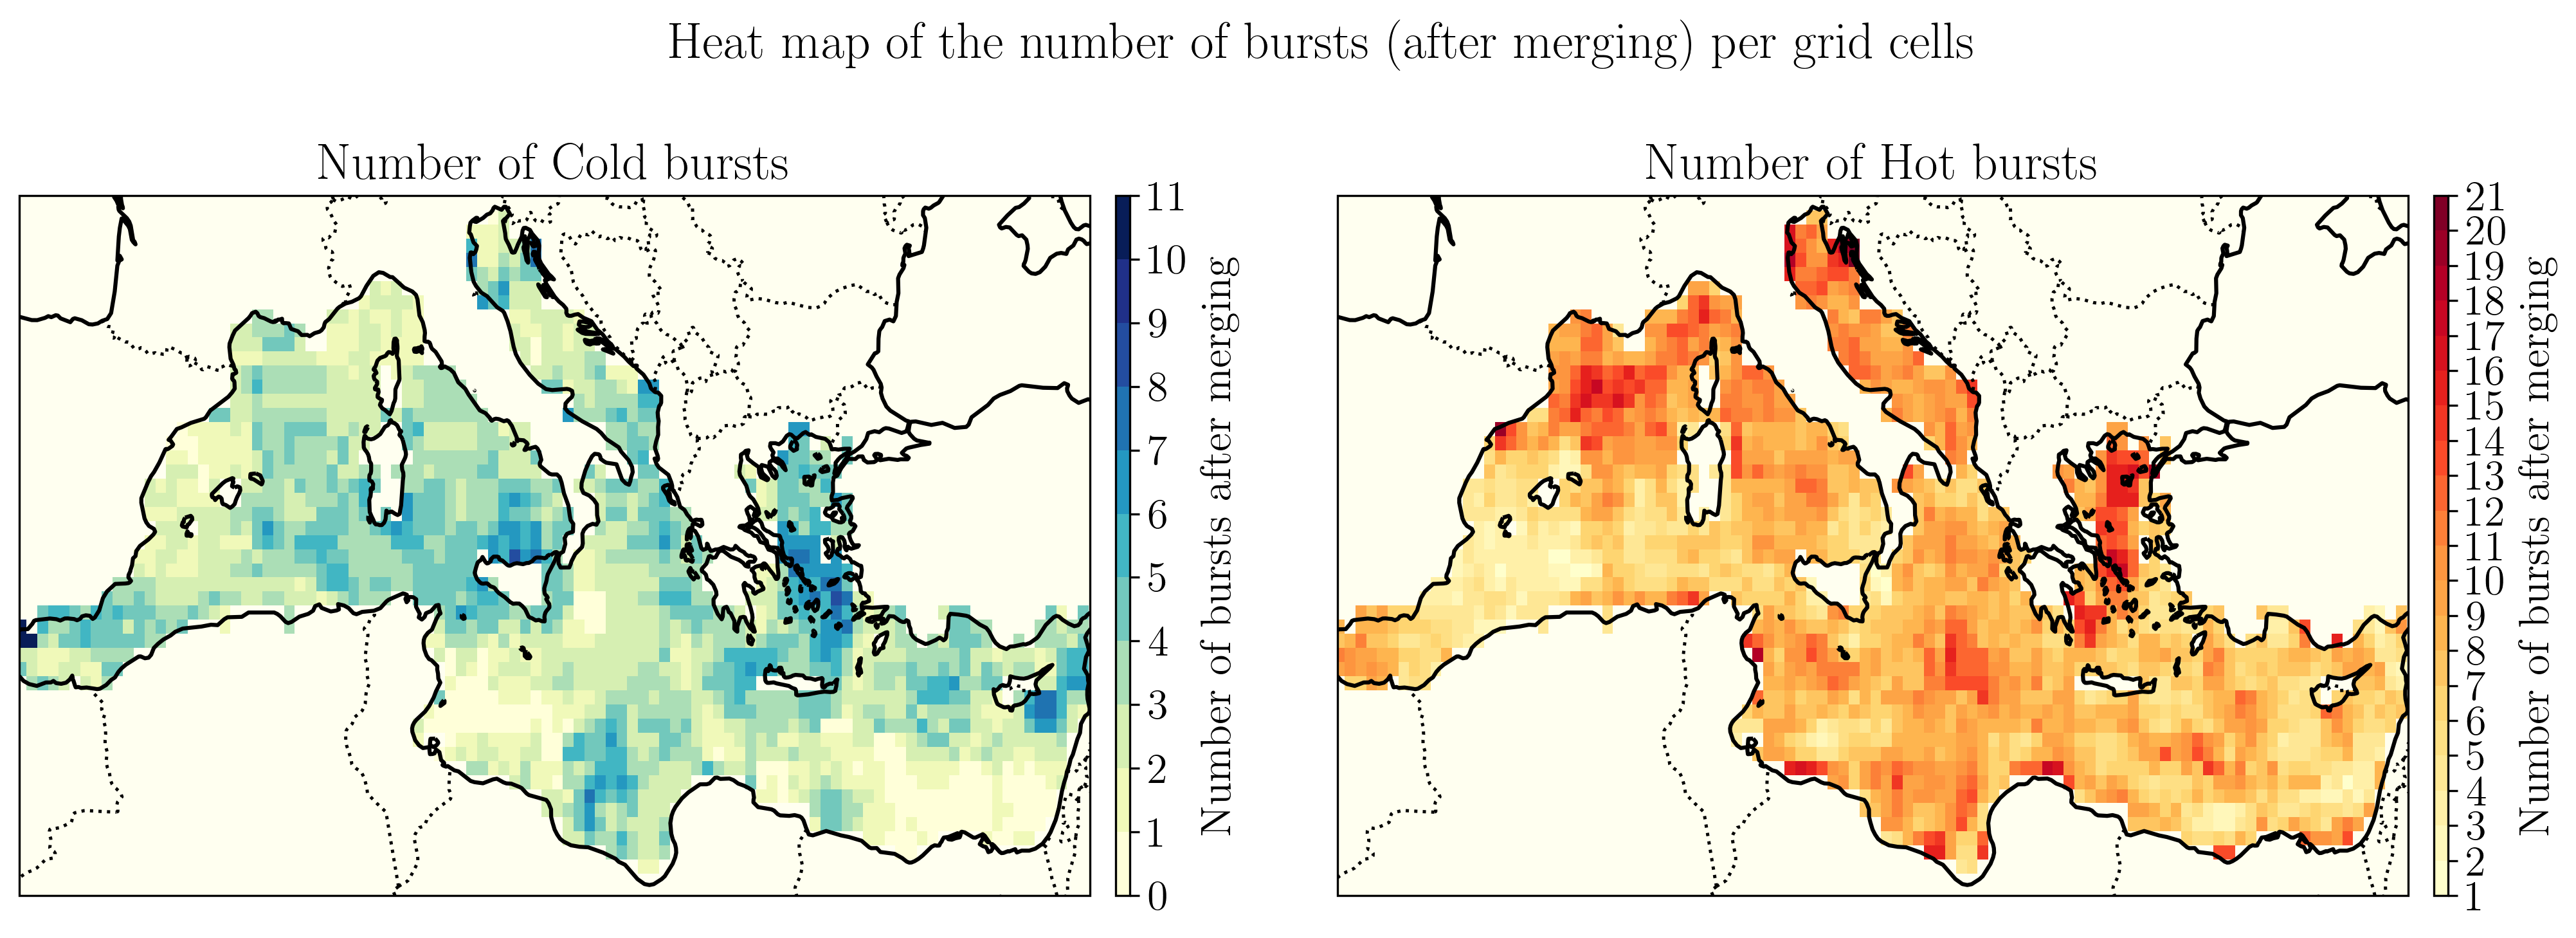

In [6]:
plt.figure(figsize=(14, 5), dpi=300)

# First subplot: Cold bursts
bounds_cold = np.arange(np.nanmin(grid_count_cold), np.nanmax(grid_count_cold)+1, 1)
if len(bounds_cold) > 1:
    ax1 = plt.subplot(1, 2, 1, projection=projection)

    cmap_cold = plt.cm.YlGnBu
    cmap_cold.set_bad(color="ivory")
    norm_cold = mcolors.BoundaryNorm(boundaries=bounds_cold, ncolors=cmap_cold.N) 
    img1 = ax1.imshow(grid_count_cold, cmap=cmap_cold, norm=norm_cold, extent=[lon_min, lon_max, lat_min, lat_max], 
                      transform=ccrs.PlateCarree(), origin='upper', aspect='auto')
    ax1.coastlines(resolution='50m', linewidth=1.5),ax1.add_feature(cf.BORDERS, linestyle=':', linewidth=1.2),ax1.set_extent([lon_min, lon_max, lat_min, lat_max], crs=crs)
    cbar1 = plt.colorbar(img1, ax=ax1, orientation='vertical', pad=0.02, aspect=50, boundaries=bounds_cold, ticks=bounds_cold)
    cbar1.set_label('Number of bursts after merging'), ub.hide_ax(ax1), ax1.set_title("Number of Cold bursts ")

# Second subplot: Hot bursts
bounds_hot = np.arange(np.nanmin(grid_count_hot), np.nanmax(grid_count_hot)+1, 1)
if len(bounds_hot) > 1:
    ax2 = plt.subplot(1, 2, 2, projection=projection)
    cmap_hot = plt.cm.YlOrRd
    cmap_hot.set_bad(color="ivory")
    norm_hot = mcolors.BoundaryNorm(boundaries=bounds_hot, ncolors=cmap_hot.N)
    img2 = ax2.imshow(grid_count_hot, cmap=cmap_hot, norm=norm_hot, extent=[lon_min, lon_max, lat_min, lat_max], 
                      transform=ccrs.PlateCarree(), origin='upper', aspect='auto')
    ax2.coastlines(resolution='50m', linewidth=1.5), ax2.add_feature(cf.BORDERS, linestyle=':', linewidth=1.2), ax2.set_extent([lon_min, lon_max, lat_min, lat_max], crs=crs)
    cbar2 = plt.colorbar(img2, ax=ax2, orientation='vertical', pad=0.02, aspect=50, boundaries=bounds_hot, ticks=bounds_hot)
    cbar2.set_label('Number of bursts after merging'), ub.hide_ax(ax2), ax2.set_title("Number of Hot bursts")

plt.suptitle("Heat map of the number of bursts (after merging) per grid cells"), plt.tight_layout()
plt.show()

In [7]:
plt.figure(figsize=(14, 5))
# First subplot: Cold bursts
if not np.isnan(np.max(grid_count_days_cold)):
    step = max( 1, int(np.nanmax(grid_count_days_cold)//20))
    bounds_cold = np.arange(np.nanmin(grid_count_days_cold), np.nanmax(grid_count_days_cold)+1, step)
    ax1 = plt.subplot(1, 2, 1, projection=projection)
    cmap_cold = plt.cm.YlGnBu
    cmap_cold.set_bad(color="ivory")
    norm_cold = mcolors.BoundaryNorm(boundaries=bounds_cold, ncolors=cmap_cold.N)
    img1 = ax1.imshow(grid_count_days_cold, cmap=cmap_cold, norm=norm_cold, extent=[lon_min, lon_max, lat_min, lat_max], 
                      transform=ccrs.PlateCarree(), origin='upper', aspect='auto')
    ax1.coastlines(resolution='50m', linewidth=1.5), ax1.add_feature(cf.BORDERS, linestyle=':', linewidth=1.2), ax1.set_extent([lon_min, lon_max, lat_min, lat_max], crs=crs)
    cbar1 = plt.colorbar(img1, ax=ax1, orientation='vertical', pad=0.02, aspect=50, boundaries=bounds_cold, ticks=bounds_cold)
    cbar1.set_label('Number of bursts days'), ax1.set_title("Number of Cold bursts days")

# Second subplot: Hot bursts
if not np.isnan(np.max(grid_count_days_hot)):
    step = max( 1, int(np.nanmax(grid_count_days_hot)//20))
    bounds_hot = np.arange(np.nanmin(grid_count_days_hot), np.nanmax(grid_count_days_hot)+1, step)
    ax2 = plt.subplot(1, 2, 2, projection=projection)
    cmap_hot = plt.cm.YlOrRd
    cmap_hot.set_bad(color="ivory")
    norm_hot = mcolors.BoundaryNorm(boundaries=bounds_hot, ncolors=cmap_hot.N)
    img2 = ax2.imshow(grid_count_days_hot, cmap=cmap_hot, norm=norm_hot, extent=[lon_min, lon_max, lat_min, lat_max], 
                      transform=ccrs.PlateCarree(), origin='upper', aspect='auto')
    ax2.coastlines(resolution='50m', linewidth=1.5), ax2.add_feature(cf.BORDERS, linestyle=':', linewidth=1.2), ax2.set_extent([lon_min, lon_max, lat_min, lat_max], crs=crs)
    cbar2 = plt.colorbar(img2, ax=ax2, orientation='vertical', pad=0.02, aspect=50, boundaries=bounds_hot, ticks=bounds_hot)
    cbar2.set_label('Number of bursts days'), ax2.set_title("Number of Hot bursts days")
plt.suptitle("Heat map of the number of days belonging to bursts per grid cells"), plt.tight_layout()
plt.show()

<Figure size 1400x500 with 0 Axes>

In [8]:
for i in range(lat):
    for j in range(lon):
        if grid_burst[i,j] == None:
            grid_burst[i,j] = []

### Connected Components

In [9]:
hot_grid_burst = np.copy(grid_burst)
for i in range(lat):
    for j in range(lon):
        if grid_burst[i,j] != []:
            l = [b for b in grid_burst[i,j] if b[-1] == 1]
            hot_grid_burst[i,j] = l
ccs = connected_components_bursts(grid_burst, 1)
ccs = [cc for cc in ccs if len(list(set(cc))) >= 5]
print(f"In total there are {len(ccs)} connected component(s). If we keep connected components that have at least 5 components (5 anomalies) we have {len(ccs)} cluster(s)") 

In total there are 607 connected component(s). If we keep connected components that have at least 5 components (5 anomalies) we have 607 cluster(s)


In [10]:
daylies_hot, daylies_cold, series_hot, series_cold = ub.compute_grid_bars(ts_date, grid_burst, coords)

In [11]:
data = {'date': ts_date, 'hot': daylies_hot}
df = pd.DataFrame(data)
df1 = df['hot'].groupby([(df.date.dt.month), (df.date.dt.year)]).sum()

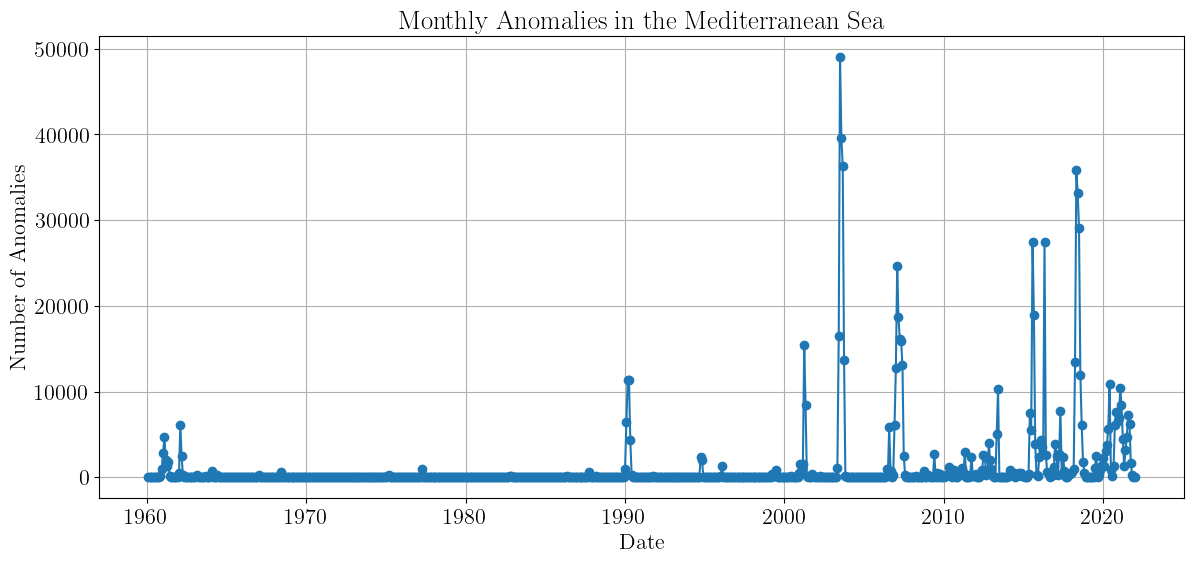

In [12]:
data = {'date': ts_date, 'hot': daylies_hot}
df = pd.DataFrame(data)
df.set_index('date', inplace=True)
monthly_df = df['hot'].resample('ME').sum()

plt.figure(figsize=(14,6))
plt.plot(monthly_df.index, monthly_df, marker='o')
plt.title('Monthly Anomalies in the Mediterranean Sea')
plt.xlabel('Date')
plt.ylabel('Number of Anomalies')
plt.grid(True)
plt.show()


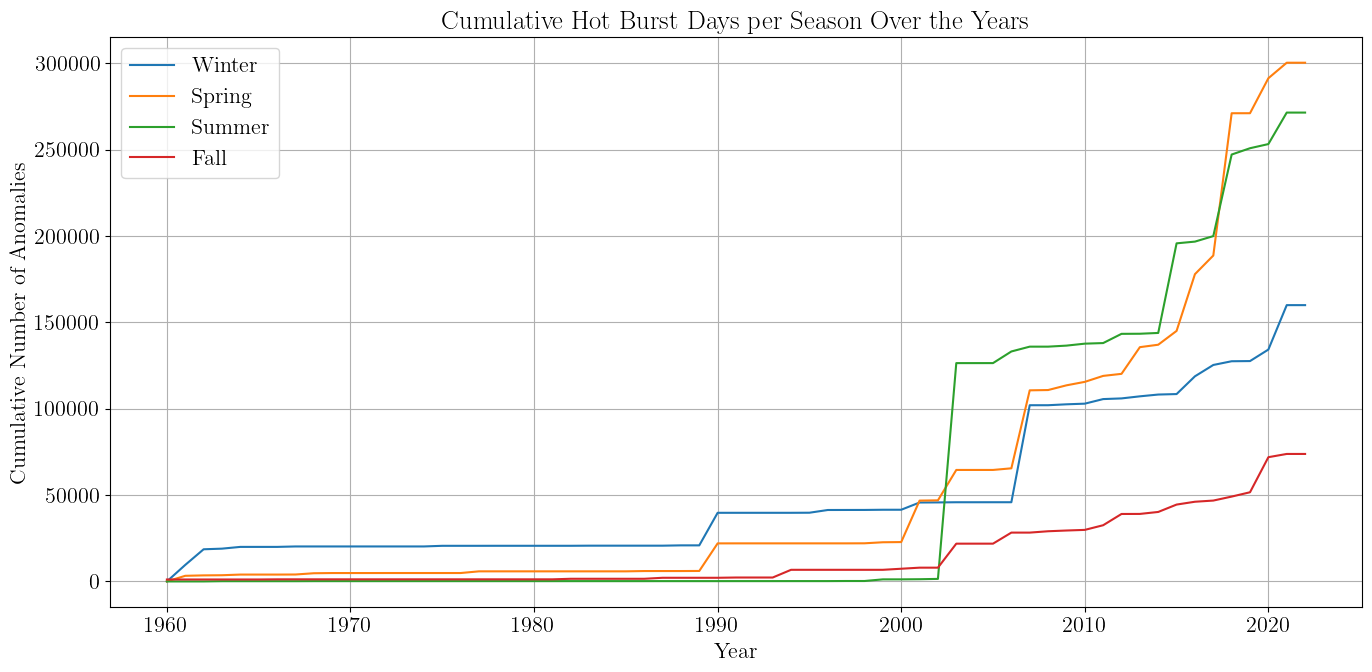

In [13]:
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'
        
df = pd.DataFrame({'date': ts_date, 'hot': daylies_hot})
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['season'] = df['month'].apply(get_season)

# Adjust year for December (so Winter 2021 = Dec 2020 + Jan/Feb 2021)
df['season_year'] = df['year']
df.loc[(df['month'] == 12), 'season_year'] += 1

seasonal_df = df.groupby(['season_year', 'season'])['hot'].sum().reset_index()
seasonal_df = seasonal_df.rename(columns={'season_year': 'year', 'hot': 'seasonal_total'})

# Pivot for plotting
pivot_df = seasonal_df.pivot(index='year', columns='season', values='seasonal_total').fillna(0)

# Cumulative sum
cumulative_df = pivot_df.cumsum()

# Plot
plt.figure(figsize=(14, 7))
for season in ['Winter', 'Spring', 'Summer', 'Fall']:
    plt.plot(cumulative_df.index, cumulative_df[season], label=season)

plt.title('Cumulative Hot Burst Days per Season Over the Years')
plt.xlabel('Year')
plt.ylabel('Cumulative Number of Anomalies')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

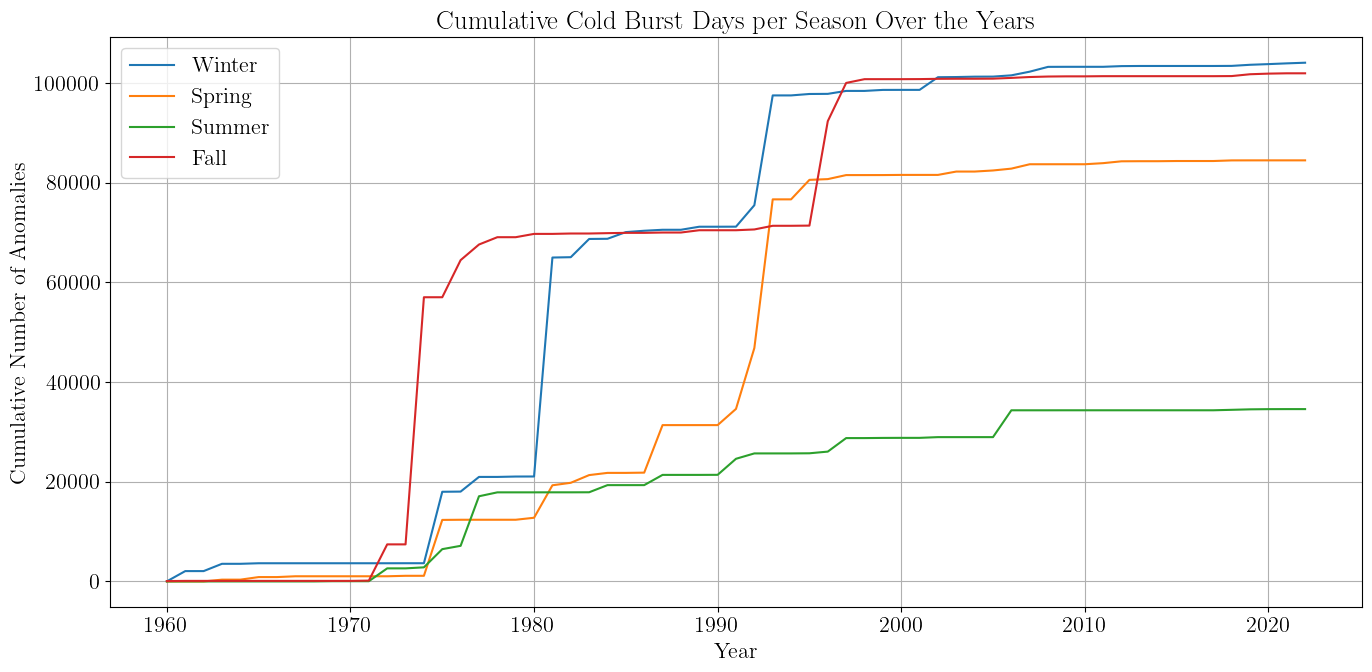

In [14]:
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'
        
df = pd.DataFrame({'date': ts_date, 'hot': daylies_cold})
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['season'] = df['month'].apply(get_season)

# Adjust year for December (so Winter 2021 = Dec 2020 + Jan/Feb 2021)
df['season_year'] = df['year']
df.loc[(df['month'] == 12), 'season_year'] += 1

seasonal_df = df.groupby(['season_year', 'season'])['hot'].sum().reset_index()
seasonal_df = seasonal_df.rename(columns={'season_year': 'year', 'hot': 'seasonal_total'})

# Pivot for plotting
pivot_df = seasonal_df.pivot(index='year', columns='season', values='seasonal_total').fillna(0)

# Cumulative sum
cumulative_df = pivot_df.cumsum()

# Plot
plt.figure(figsize=(14, 7))
for season in ['Winter', 'Spring', 'Summer', 'Fall']:
    plt.plot(cumulative_df.index, cumulative_df[season], label=season)

plt.title('Cumulative Cold Burst Days per Season Over the Years')
plt.xlabel('Year')
plt.ylabel('Cumulative Number of Anomalies')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

<>:15: SyntaxWarning: invalid escape sequence '\%'
<>:15: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_10837/3494890618.py:15: SyntaxWarning: invalid escape sequence '\%'
  plt.ylabel('Grid coverage (\%)')


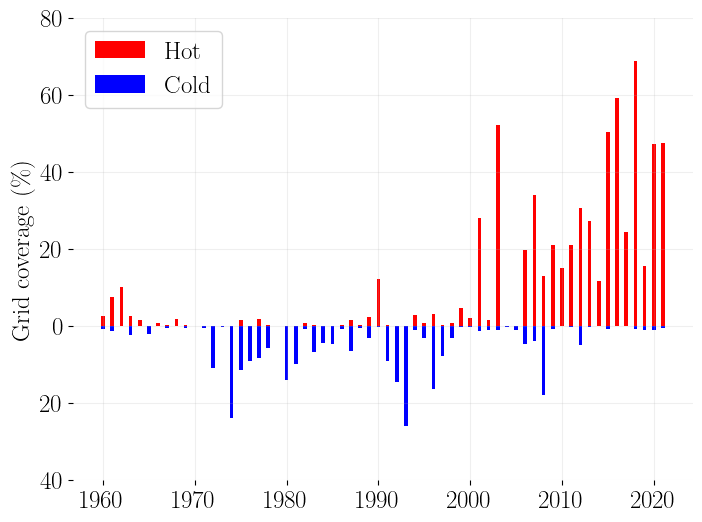

In [15]:
data = {'year': years,
        'hot': series_hot,
        'cold': -series_cold}

plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  
    "font.serif": ["Latin Modern Roman"],
})
plt.rcParams['font.size'] = 18
plt.figure(figsize=(8, 6)), plt.grid(alpha=0.2)
plt.bar(data['year'], data['hot']/len(valid_coordinates)*100, width=0.4, color='red', label='Hot')
plt.bar(data['year'], data['cold']/len(valid_coordinates)*100, width=0.4, color='blue', label='Cold')
plt.ylabel('Grid coverage (\%)')
ax = plt.gca()
ax.set_yticks(ax.get_yticks().tolist())
#ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
labels = [int(abs(e)) for e in ax.get_yticks()]
ax.set_yticklabels(labels), plt.legend()
for pos in ['right', 'top', 'bottom', 'left']: plt.gca().spines[pos].set_visible(False)

plt.savefig("grid_coverage.pdf", format="pdf", bbox_inches='tight')

plt.show()

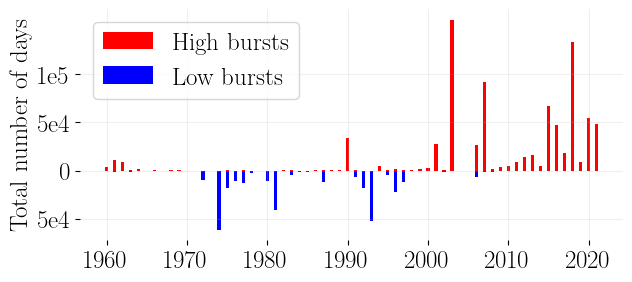

In [16]:
data = {'date': ts_date,
        'hot': daylies_hot,
        'cold': -daylies_cold}

plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  
    "font.serif": ["Latin Modern Roman"],
})
plt.rcParams['font.size'] = 18

df = pd.DataFrame(data)
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year


yearly_sum = df.groupby('year')[['hot', 'cold']].sum().reset_index()

plt.figure(figsize=(7, 3)), plt.grid(alpha=0.2)
plt.bar(yearly_sum['year'], yearly_sum['hot'], width=0.4, color='red', label='High bursts')
plt.bar(yearly_sum['year'], yearly_sum['cold'], width=0.4, color='blue', label='Low bursts')
plt.ylabel('Total number of days')
ax = plt.gca()
custom_positions = [-50000, 0, 50000, 100000]  
custom_labels = ['5e4', '0', '5e4', '1e5']  
ax.set_yticks(custom_positions)         
ax.set_yticklabels(custom_labels)       

plt.legend(loc = "upper left")
#ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
for pos in ['right', 'top', 'bottom', 'left']: plt.gca().spines[pos].set_visible(False)
plt.savefig("../figures/yearly_days.pdf", format="pdf", bbox_inches='tight')

plt.savefig("grid_cumul.pdf", format="pdf", bbox_inches='tight')

plt.show()

In [17]:
len(valid_coordinates)

4120

In [18]:
def grid_length(cc):
    coords = []
    for (i, j, _) in cc:
        if not (i,j) in coords:
            coords.append((i,j))
    return len(coords)
    

ccs_f = [cc for cc in ccs if grid_length(cc) >= 42]

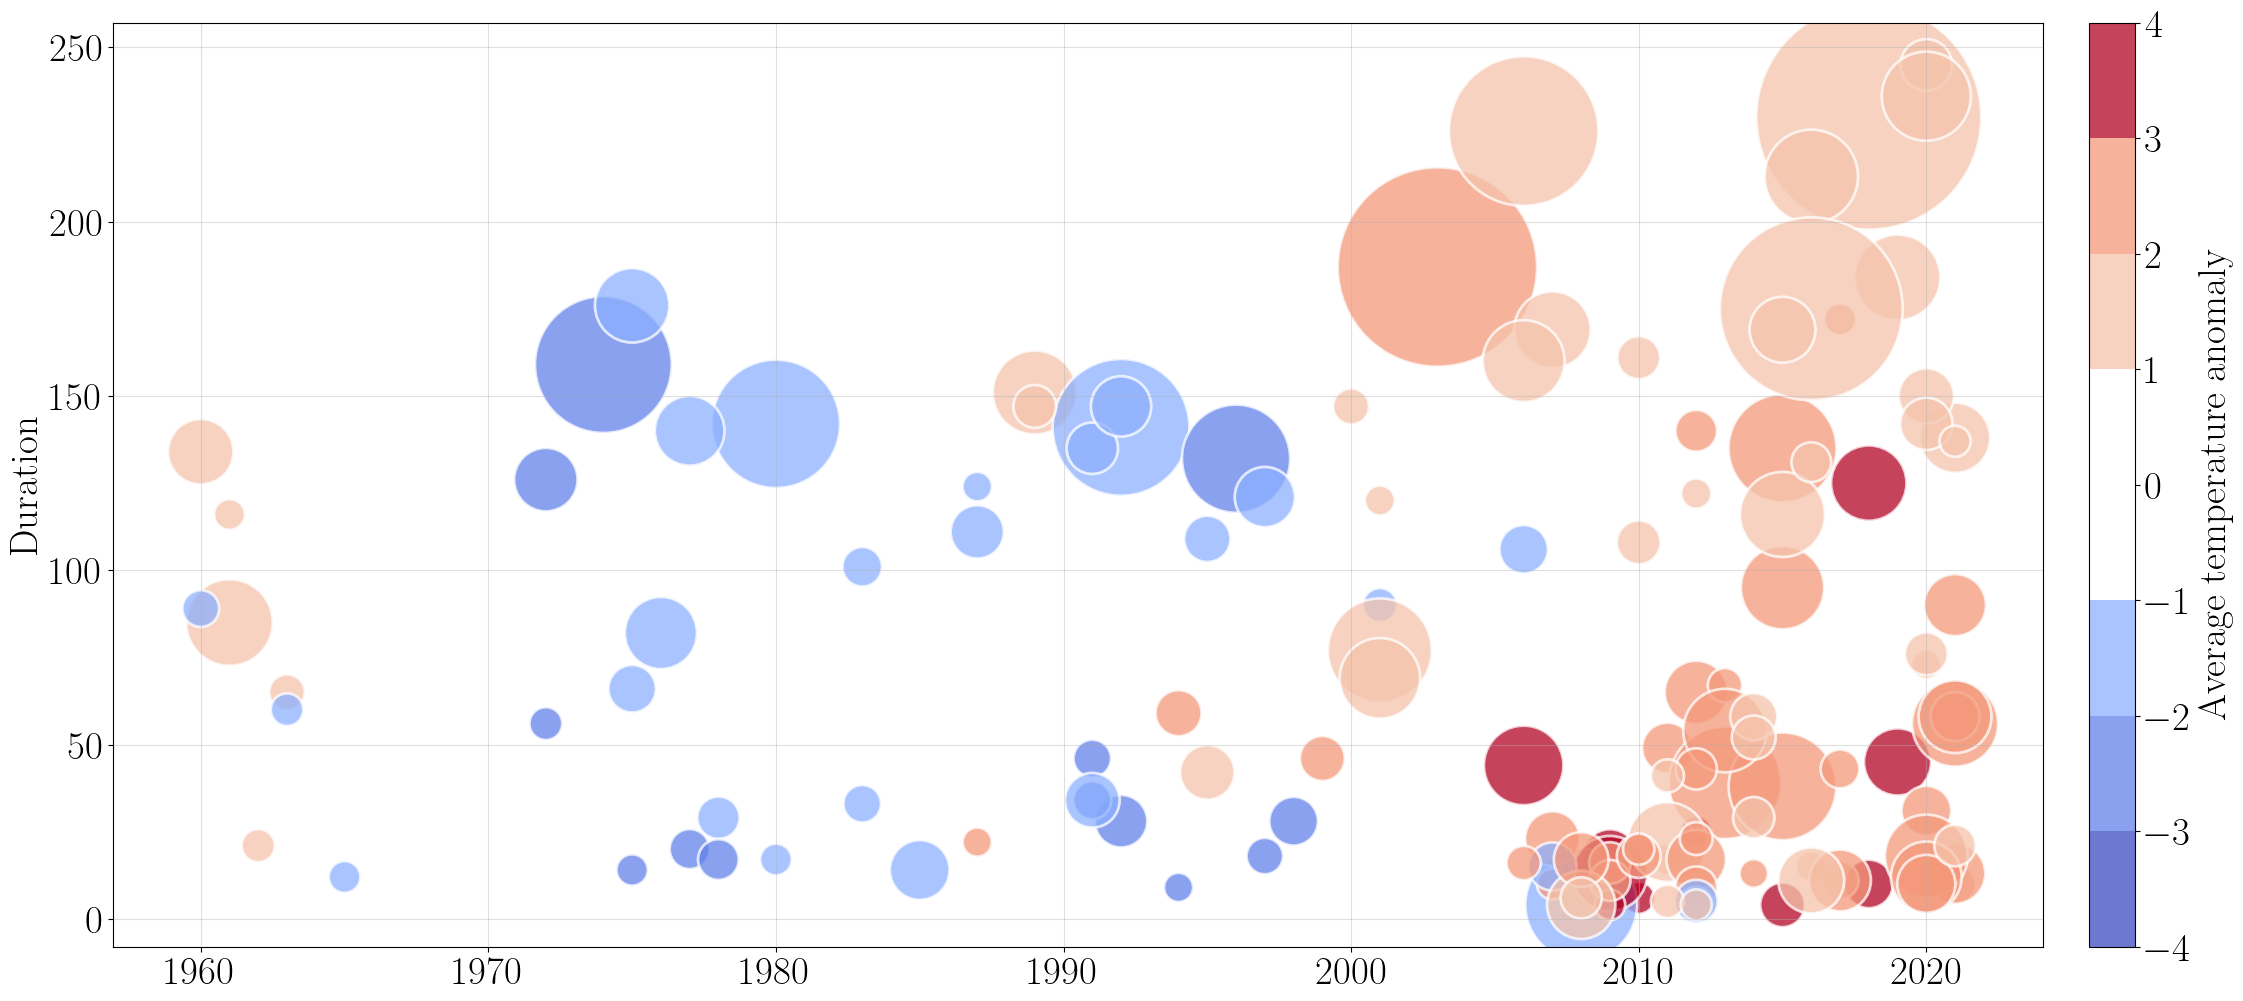

In [19]:
cc_stats, grid_start_5, grid_start_10, grid_start_15, grid_start_20 = ub.compute_cc_stats(grid.values, grid_burst, ccs_f, n_year, first_year, lat, lon, coords)

plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  
    "font.serif": ["Latin Modern Roman"],
})
plt.rcParams['font.size'] = 28

df_cc = pd.DataFrame(cc_stats, columns=['Duration', 'Spatial Size', 'Start Year', 'Type', 'Intensity'])
df_cc = df_cc[df_cc['Duration'] >= 4]
# Setting the color based on Type
colors = df_cc['Type'].map({1: 'red', -1: 'blue'})

cmap = plt.cm.coolwarm
bounds = np.arange(-4, 5, 1)
colors = cmap(np.linspace(0, 1, 9))
colors[3:5] = [1, 1, 1, 1]  # Middle value becomes white
custom_cmap = mcolors.ListedColormap(colors)

bounds = np.arange(-4, 5, 1)
norm = mcolors.BoundaryNorm(boundaries=bounds, ncolors=custom_cmap.N)
# Creating the bubble plot
plt.figure(figsize=(30, 12))
plt.scatter(df_cc['Start Year'], df_cc['Duration'], s=df_cc['Spatial Size']*10, c=df_cc['Intensity'], alpha=0.75, cmap=custom_cmap, norm=norm, edgecolors="w", linewidth=2)

# Adding labels and title
plt.ylabel('Duration')
#plt.title('Bubble Plot: Duration vs Year with Spatial Size as Bubble Size and Type as Color')
plt.colorbar(pad = 0.02, label="Average temperature anomaly")
plt.grid(alpha=0.4)


plt.savefig("bubble_plot.pdf", format="pdf", bbox_inches='tight')

plt.show()

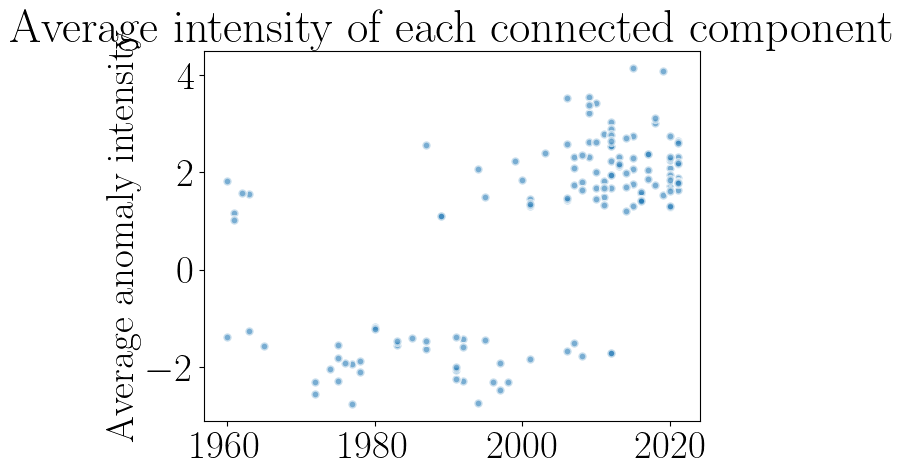

In [20]:
plt.scatter(df_cc['Start Year'], df_cc['Intensity'], alpha=0.6, edgecolors="w", linewidth=2)
plt.ylabel("Average anomaly intensity")
plt.title("Average intensity of each connected component")
plt.show()

In [21]:
hot_df = df_cc[df_cc['Type'] == 1].copy()
cold_df = df_cc[df_cc['Type'] == -1].copy()

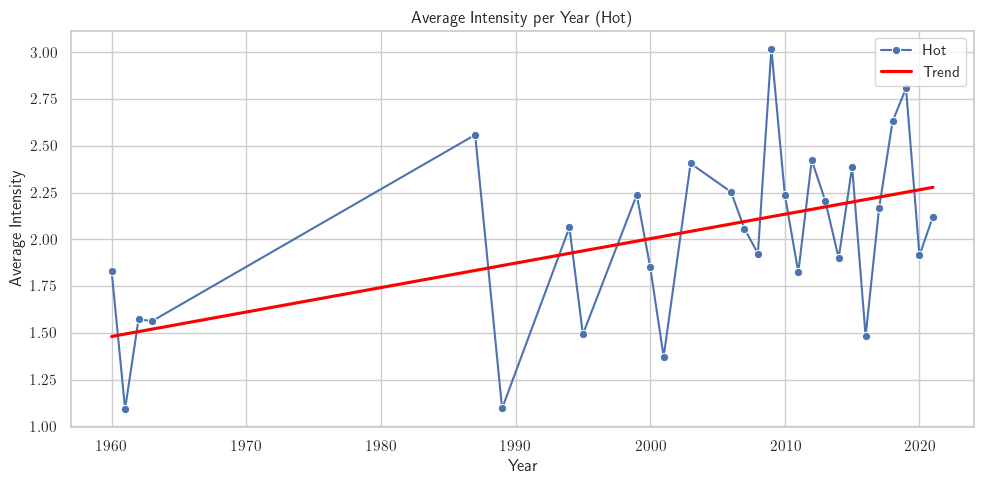

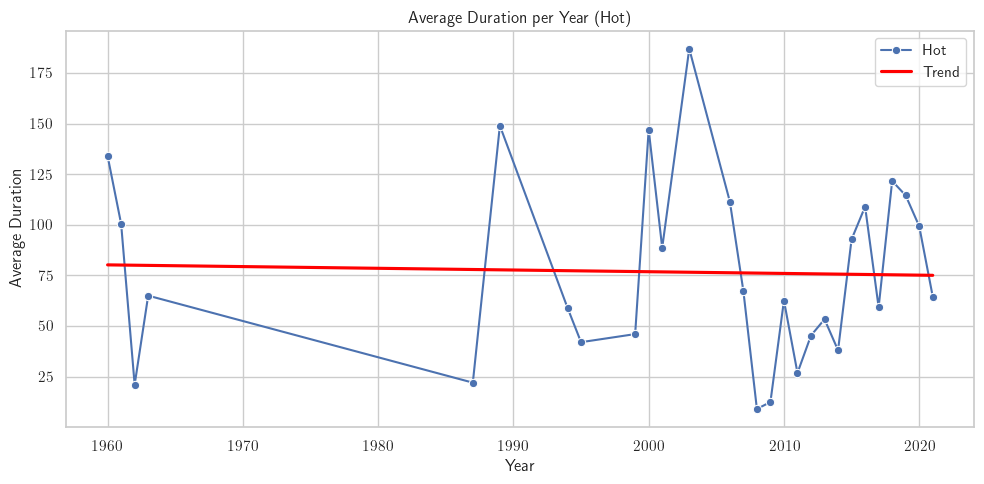

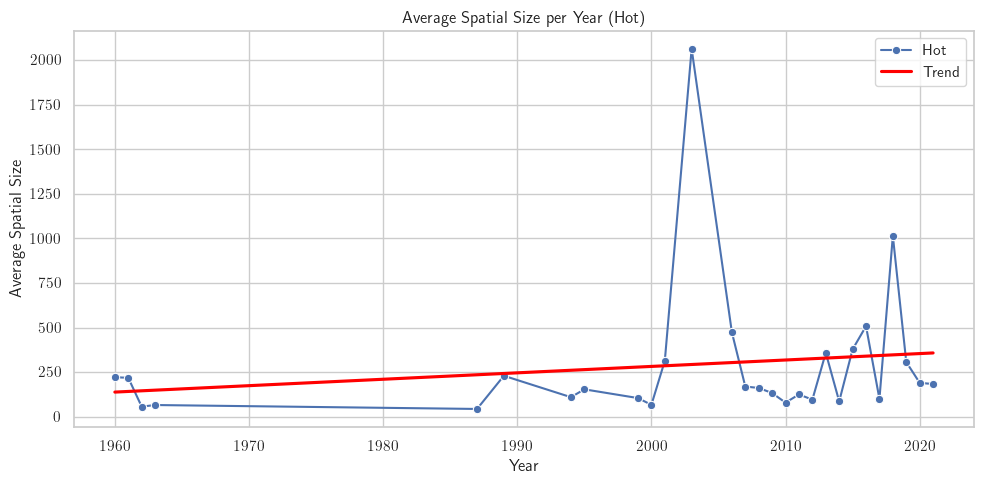

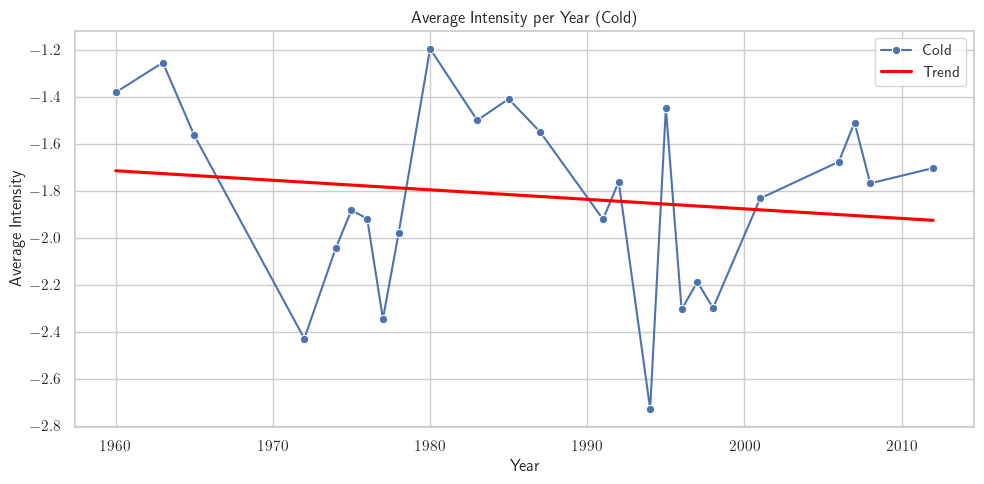

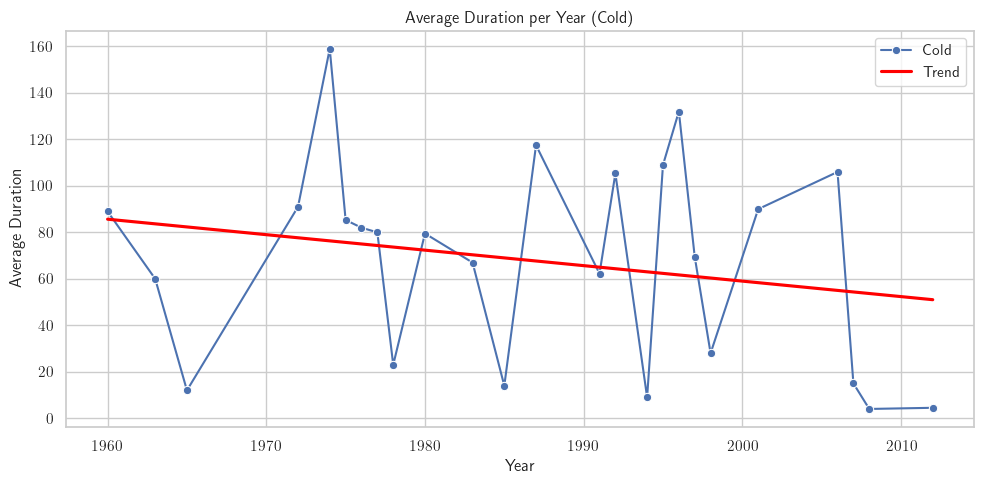

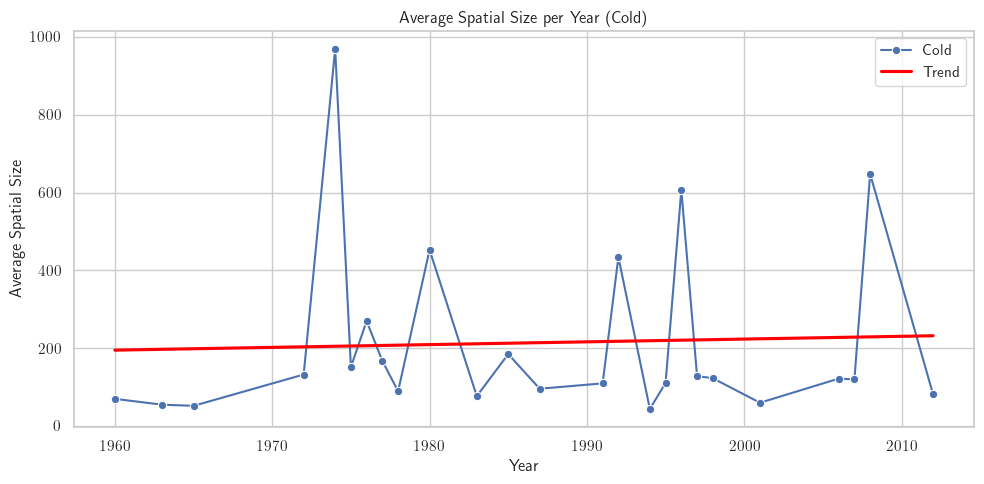

In [22]:
sns.set(style="whitegrid")

# Assuming you already have hot_df and cold_df
def plot_avg_trend(df, column, label):
    # Group by year and calculate average
    yearly_avg = df.groupby('Start Year')[column].mean().reset_index()

    # Plot average and trend
    plt.figure(figsize=(10, 5))
    sns.lineplot(data=yearly_avg, x='Start Year', y=column, marker='o', label=label)
    sns.regplot(data=yearly_avg, x='Start Year', y=column,
                scatter=False, ci=None, label='Trend', color='red')

    plt.title(f'Average {column} per Year ({label})')
    plt.ylabel(f'Average {column}')
    plt.xlabel('Year')
    plt.legend()
    plt.tight_layout()
    plt.show()

# Plot for hot events
plot_avg_trend(hot_df, 'Intensity', 'Hot')
plot_avg_trend(hot_df, 'Duration', 'Hot')
plot_avg_trend(hot_df, 'Spatial Size', 'Hot')

# Plot for cold events
plot_avg_trend(cold_df, 'Intensity', 'Cold')
plot_avg_trend(cold_df, 'Duration', 'Cold')
plot_avg_trend(cold_df, 'Spatial Size', 'Cold')

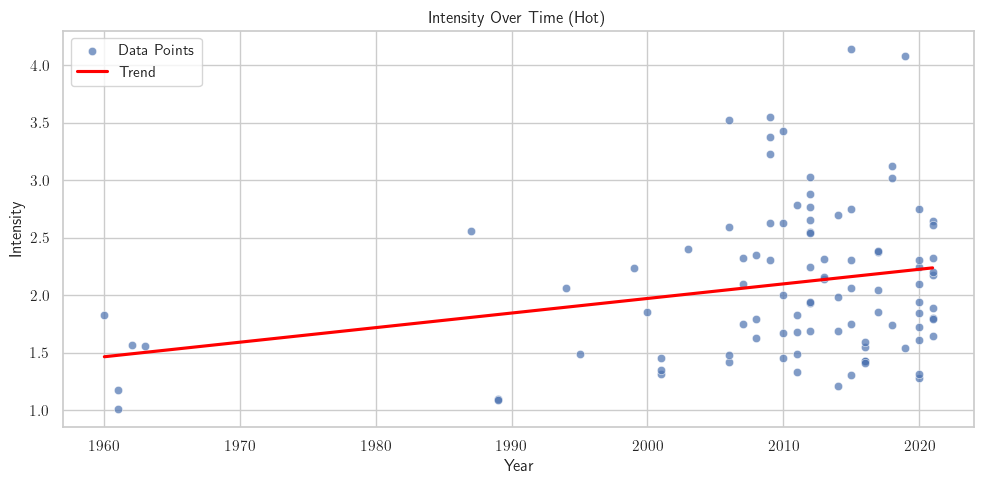

Hot — Intensity Slope: 0.0127


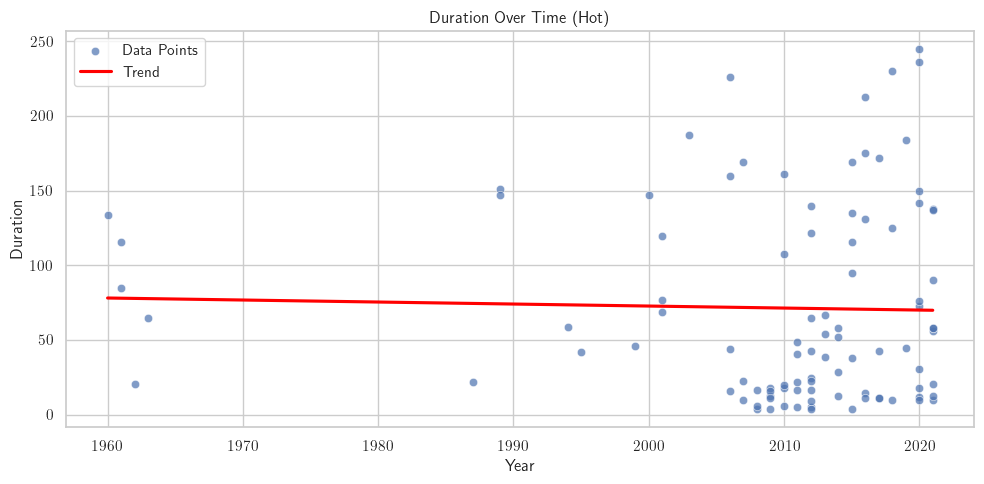

Hot — Duration Slope: -0.1344


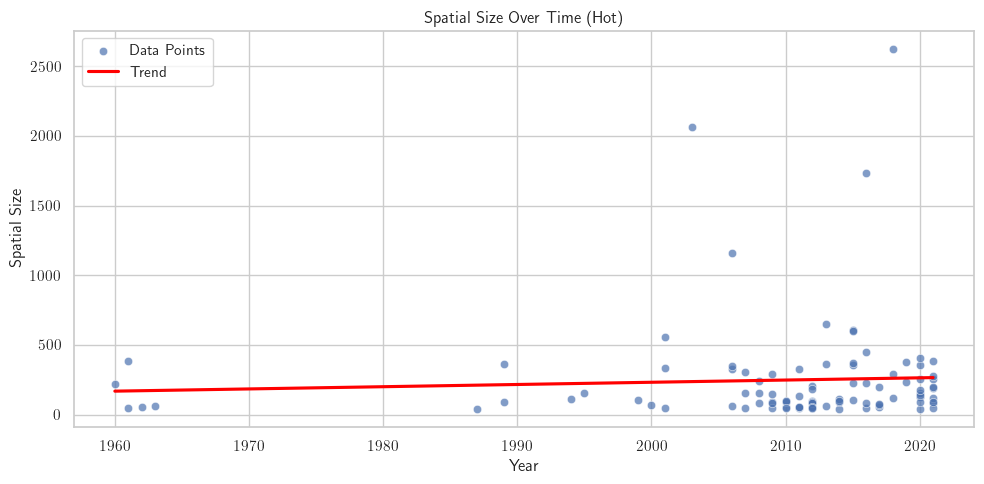

Hot — Spatial Size Slope: 1.5939


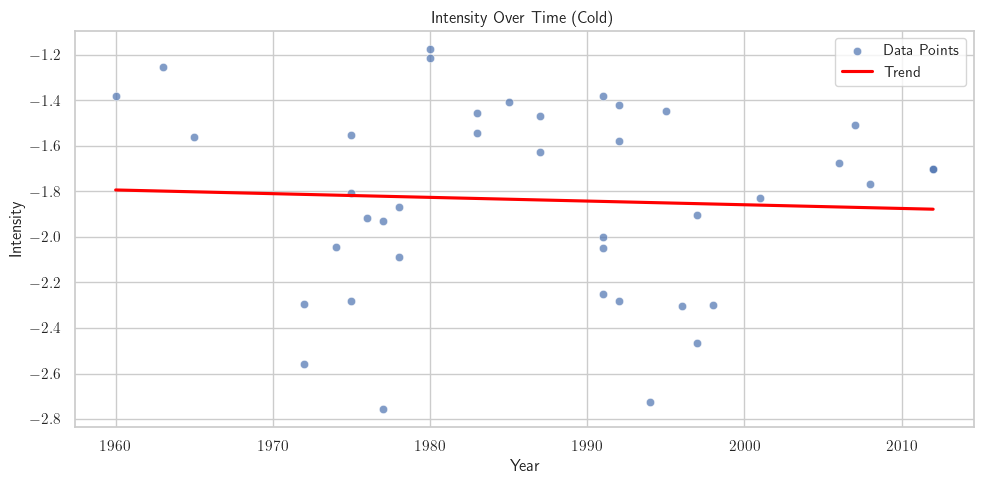

Cold — Intensity Slope: -0.0016


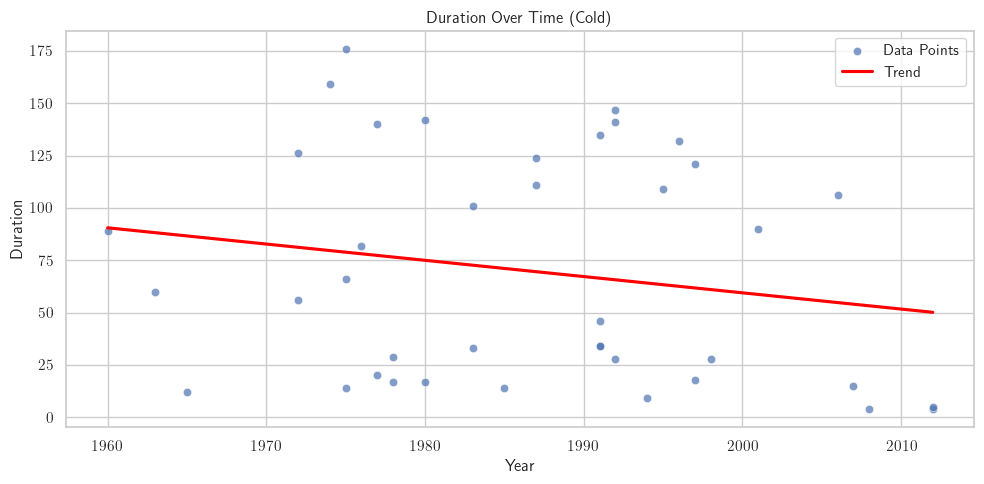

Cold — Duration Slope: -0.7761


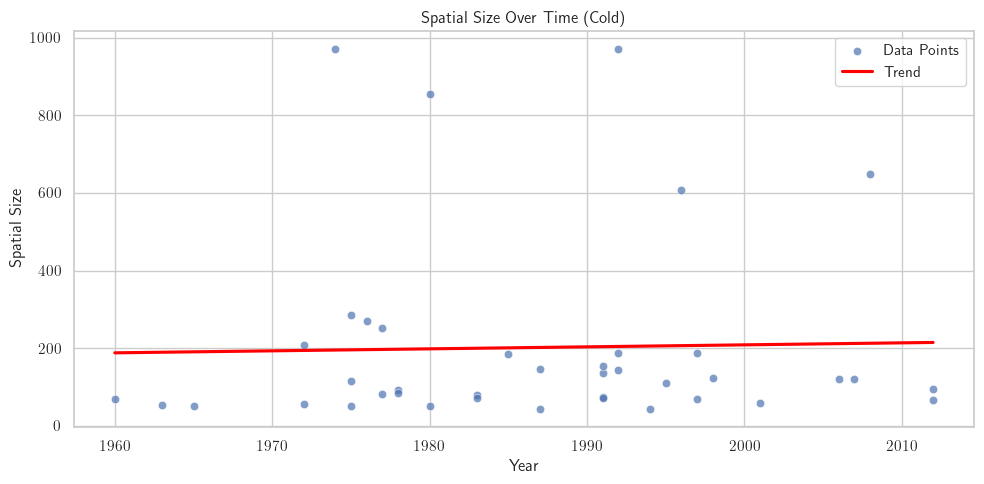

Cold — Spatial Size Slope: 0.5135


In [23]:
# Function to plot all values with trend
from scipy.stats import linregress
def plot_all_values(df, column, label):
    plt.figure(figsize=(10, 5))
    
    # Plot all data points
    sns.scatterplot(data=df, x='Start Year', y=column, label='Data Points', alpha=0.7)
    slope, intercept, r_value, p_value, std_err = linregress(df['Start Year'], df[column])
    # Add linear trend line
    sns.regplot(data=df, x='Start Year', y=column, scatter=False, ci=None, color='red', label='Trend')

    plt.title(f'{column} Over Time ({label})')
    plt.ylabel(column)
    plt.xlabel('Year')
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f'{label} — {column} Slope: {slope:.4f}')


# Plot for hot events
plot_all_values(hot_df, 'Intensity', 'Hot')
plot_all_values(hot_df, 'Duration', 'Hot')
plot_all_values(hot_df, 'Spatial Size', 'Hot')

# Plot for cold events
plot_all_values(cold_df, 'Intensity', 'Cold')
plot_all_values(cold_df, 'Duration', 'Cold')
plot_all_values(cold_df, 'Spatial Size', 'Cold')

In [24]:
hot_counts = hot_df.groupby('Start Year').size().rename('Count')
hot_df = hot_df.merge(hot_counts, on='Start Year')

# Add 'Count' column to cold_df
cold_counts = cold_df.groupby('Start Year').size().rename('Count')
cold_df = cold_df.merge(cold_counts, on='Start Year')


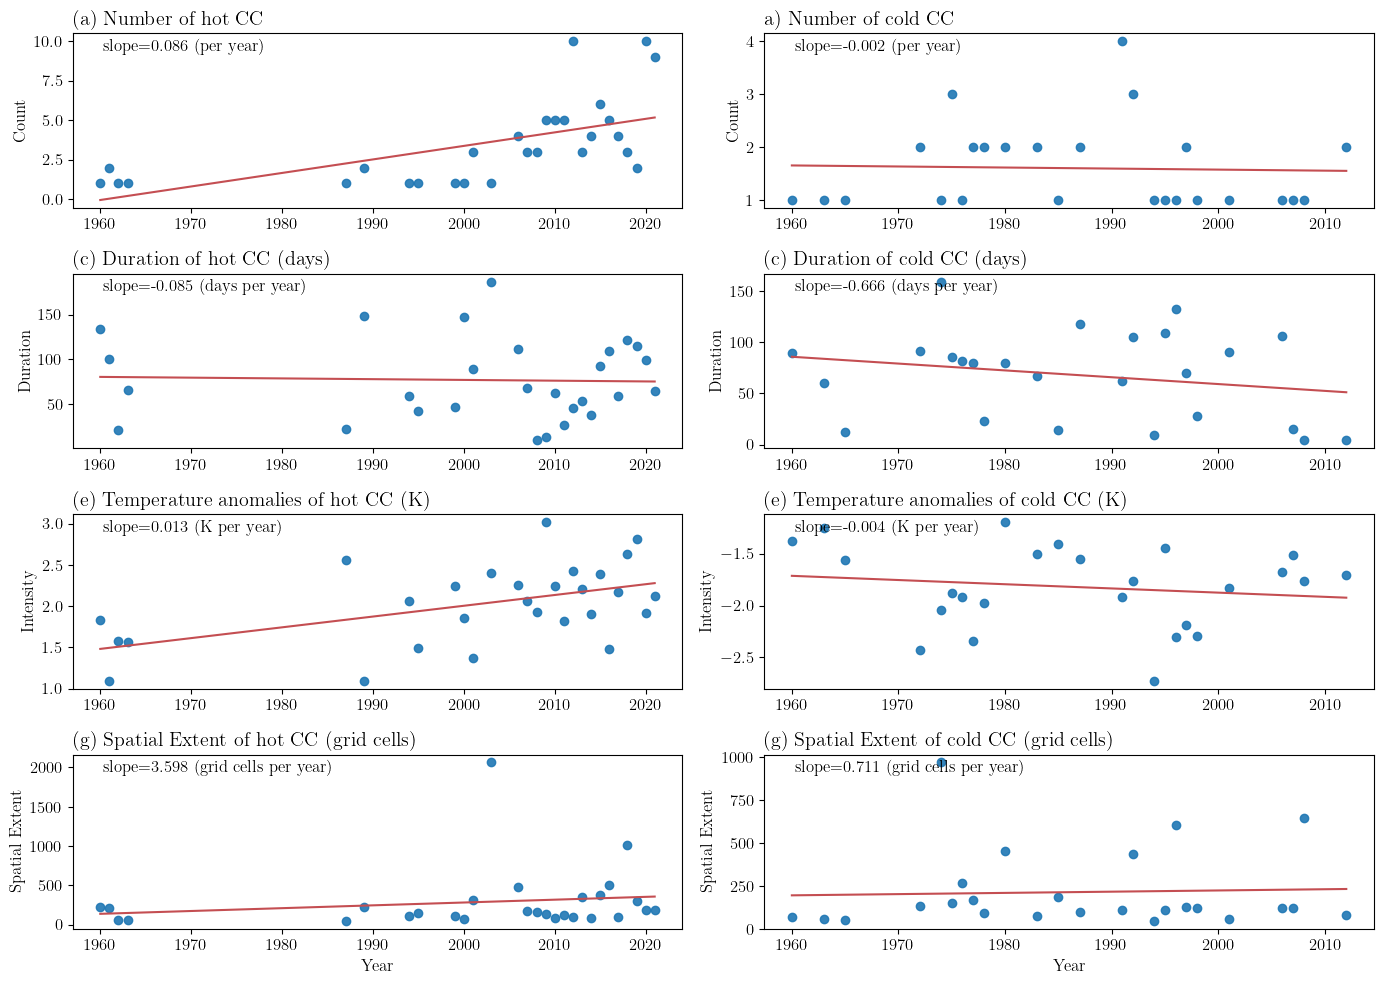

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress
import numpy as np

full_years = np.arange(min(hot_df['Start Year'].min(), cold_df['Start Year'].min()),
                      max(hot_df['Start Year'].max(), cold_df['Start Year'].max()) + 1)


def get_mean_per_year(df, year_col, value_col, full_years):
    # Group by year and compute the mean
    mean_series = df.groupby(year_col)[value_col].mean()

    # Reindex with full year range, fill missing with 0
    #mean_series = mean_series.reindex(full_years, fill_value=0)

    # Return as a DataFrame
    return mean_series.reset_index().rename(columns={year_col: 'Start Year', value_col: value_col})

def plot_subplot(ax, df, x_col, y_col, title, units=''):
    df = get_mean_per_year(df, x_col, y_col, full_years)
    # Scatter plot
    ax.plot(df[x_col], df[y_col], 'o', alpha=0.9)

    # Linear regression
    slope, intercept, r_value, p_value, std_err = linregress(df[x_col], df[y_col])

    # Sort x values for plotting
    x_vals =df[x_col].unique()
    y_vals = intercept + slope * x_vals
    # Plot regression line 
    ax.plot(x_vals, y_vals, 'r-')

    
    # Title and slope annotation
    ax.set_title(title, loc='left')
    ax.annotate(f'slope={slope:.3f} {units}', xy=(0.05, 0.9), xycoords='axes fraction')

    ax.set_ylabel(y_col)
    ax.set_xlabel('')


plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  
    "font.serif": ["Latin Modern Roman"],
})
plt.rcParams['font.size'] = 12

fig, axs = plt.subplots(4, 2, figsize=(14, 10))
plt.subplots_adjust(hspace=0.6, wspace=0.3)
#plt.grid(alpha=0.5)

# Plot hot events
plot_subplot(axs[0, 0], hot_df, 'Start Year', 'Count', '(a) Number of hot CC', '(per year)')
plot_subplot(axs[1, 0], hot_df, 'Start Year', 'Duration', '(c) Duration of  hot CC (days)', '(days per year)')
plot_subplot(axs[2, 0], hot_df, 'Start Year', 'Intensity', '(e) Temperature anomalies of hot CC (K)', '(K per year)')
plot_subplot(axs[3, 0], hot_df, 'Start Year', 'Spatial Size', '(g) Spatial Extent of hot CC (grid cells)', '(grid cells per year)')

plot_subplot(axs[0, 1], cold_df, 'Start Year', 'Count', 'a) Number of cold CC', '(per year)')
plot_subplot(axs[1, 1], cold_df, 'Start Year', 'Duration', '(c) Duration of  cold CC (days)', '(days per year)')
plot_subplot(axs[2, 1], cold_df, 'Start Year', 'Intensity', '(e) Temperature anomalies of cold CC (K)', '(K per year)')
plot_subplot(axs[3, 1], cold_df, 'Start Year', 'Spatial Size', '(g) Spatial Extent of cold CC (grid cells)', '(grid cells per year)')

# Set common x-labels
for ax in axs[3]:
    ax.set_xlabel('Year')

# Optional: Set common y-labels if desired
#for i in range(4):


axs[3, 0].set_ylabel('Spatial Extent')
axs[3, 1].set_ylabel('Spatial Extent')


plt.tight_layout()
plt.savefig("all_trends.pdf", format="pdf", bbox_inches='tight')
plt.show()

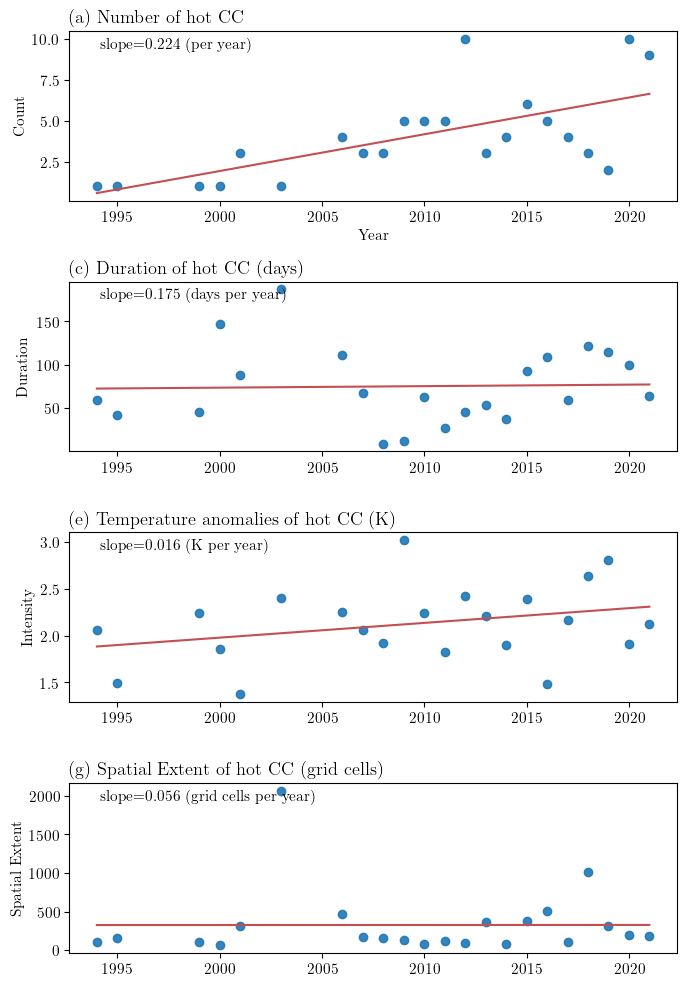

In [41]:

plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  
    "font.serif": ["Latin Modern Roman"],
})
plt.rcParams['font.size'] = 11

fig, axs = plt.subplots(4, 1, figsize=(7, 10))
plt.subplots_adjust(hspace=0.6, wspace=0.3)
#plt.grid(alpha=0.5)

hot_df_2 = hot_df[hot_df['Start Year'] >= 1990] 
# Plot hot events
plot_subplot(axs[0], hot_df_2, 'Start Year', 'Count', '(a) Number of hot CC', '(per year)')
plot_subplot(axs[1], hot_df_2, 'Start Year', 'Duration', '(c) Duration of  hot CC (days)', '(days per year)')
plot_subplot(axs[2], hot_df_2, 'Start Year', 'Intensity', '(e) Temperature anomalies of hot CC (K)', '(K per year)')
plot_subplot(axs[3], hot_df_2, 'Start Year', 'Spatial Size', '(g) Spatial Extent of hot CC (grid cells)', '(grid cells per year)')


# Set common x-labels
axs[0].set_xlabel('Year')

# Optional: Set common y-labels if desired
#for i in range(4):


axs[3].set_ylabel('Spatial Extent')


plt.tight_layout()
plt.savefig("focus_trends.pdf", format="pdf", bbox_inches='tight')
plt.show()


--- Intensity ---
Trend: increasing
Sen's Slope: 0.0126 per year
p-value: 0.0380
Hypothesis rejected: True


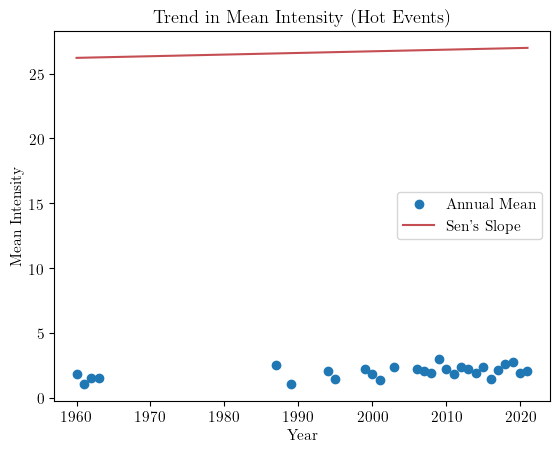

In [27]:
import pymannkendall as mk
import pandas as pd
import numpy as np

def compute_trend(df, year_col, value_col):
    # Fill in missing years with 0s
    all_years = pd.Series(np.arange(df[year_col].min(), df[year_col].max() + 1), name=year_col)
    series = df.groupby(year_col)[value_col].mean().reindex(all_years)#, fill_value=0)

    # Apply Mann-Kendall test
    result = mk.original_test(series)

    print(f"\n--- {value_col} ---")
    print(f"Trend: {result.trend}")
    print(f"Sen's Slope: {result.slope:.4f} per year")
    print(f"p-value: {result.p:.4f}")
    print(f"Hypothesis rejected: {result.h}")

    return series, result
series, result = compute_trend(hot_df, 'Start Year', 'Intensity')

years = series.index
plt.plot(years, series.values, 'o', label='Annual Mean')
plt.plot(years, result.intercept + result.slope * years, 'r-', label="Sen's Slope")
plt.title("Trend in Mean Intensity (Hot Events)")
plt.xlabel("Year")
plt.ylabel("Mean Intensity")
plt.legend()
plt.show()

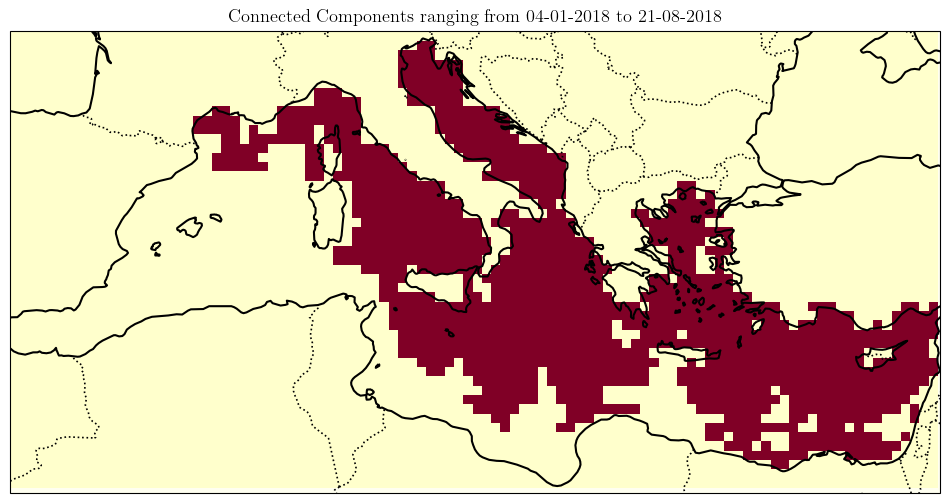

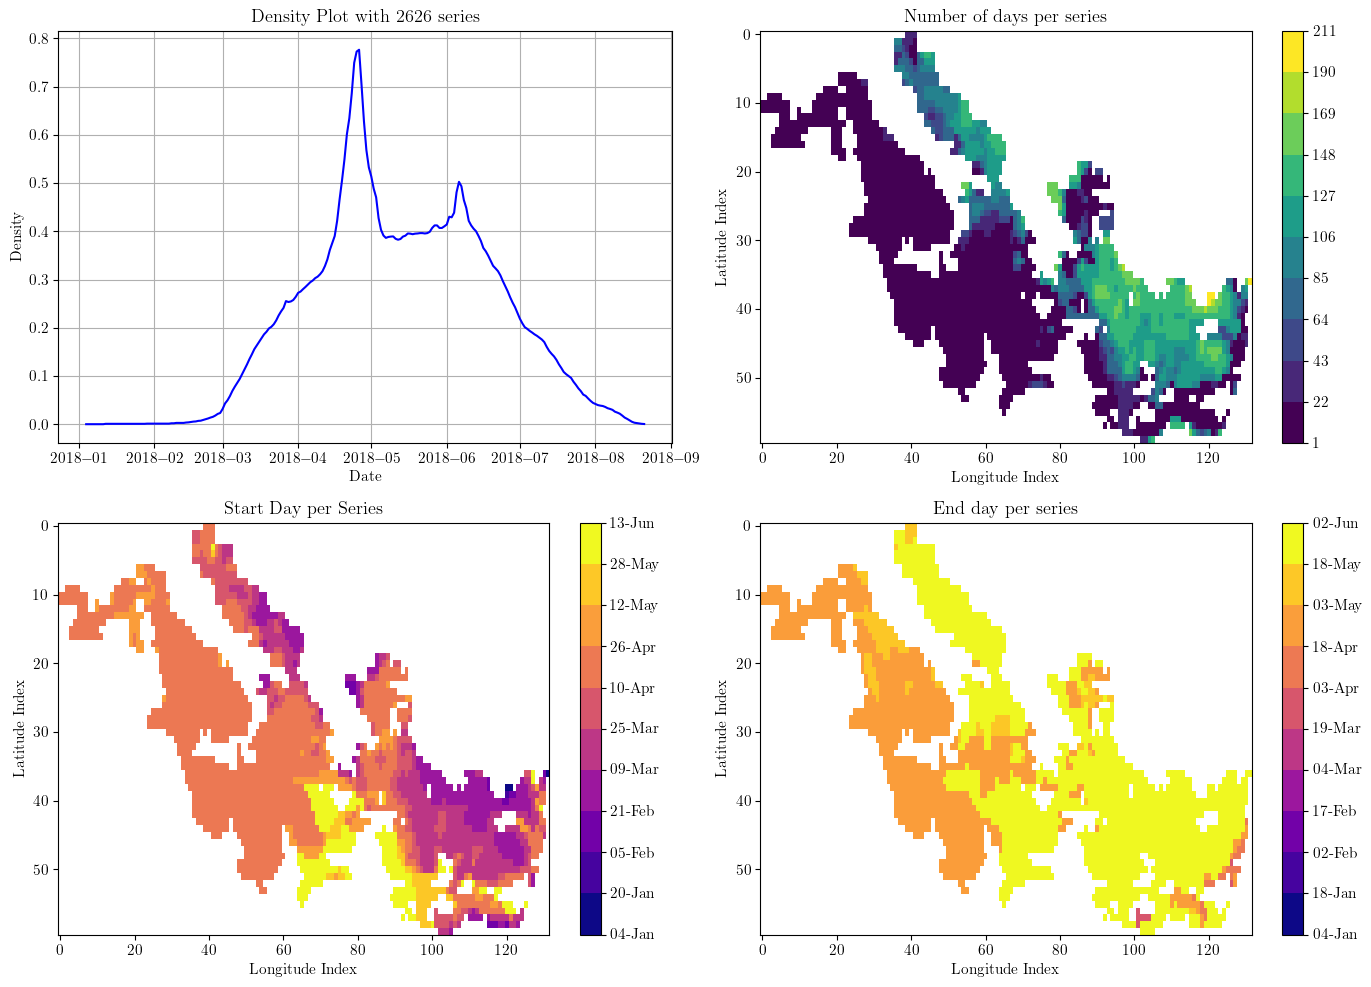

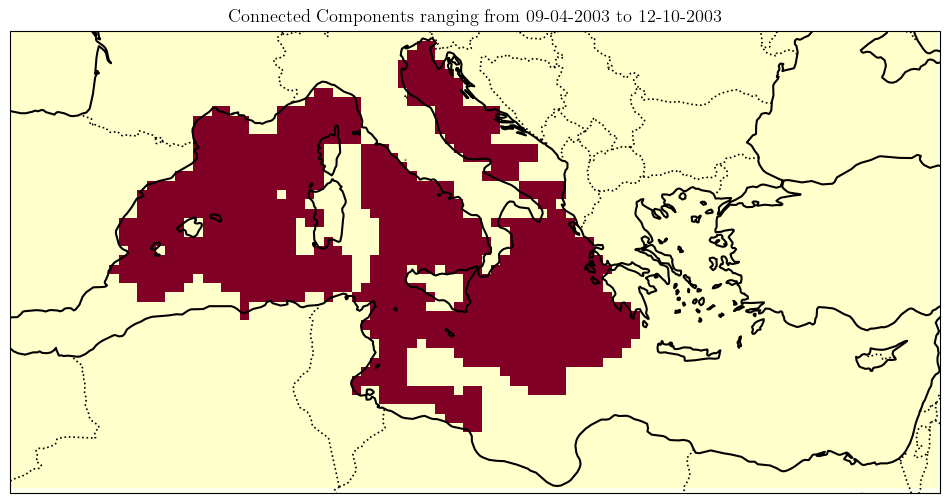

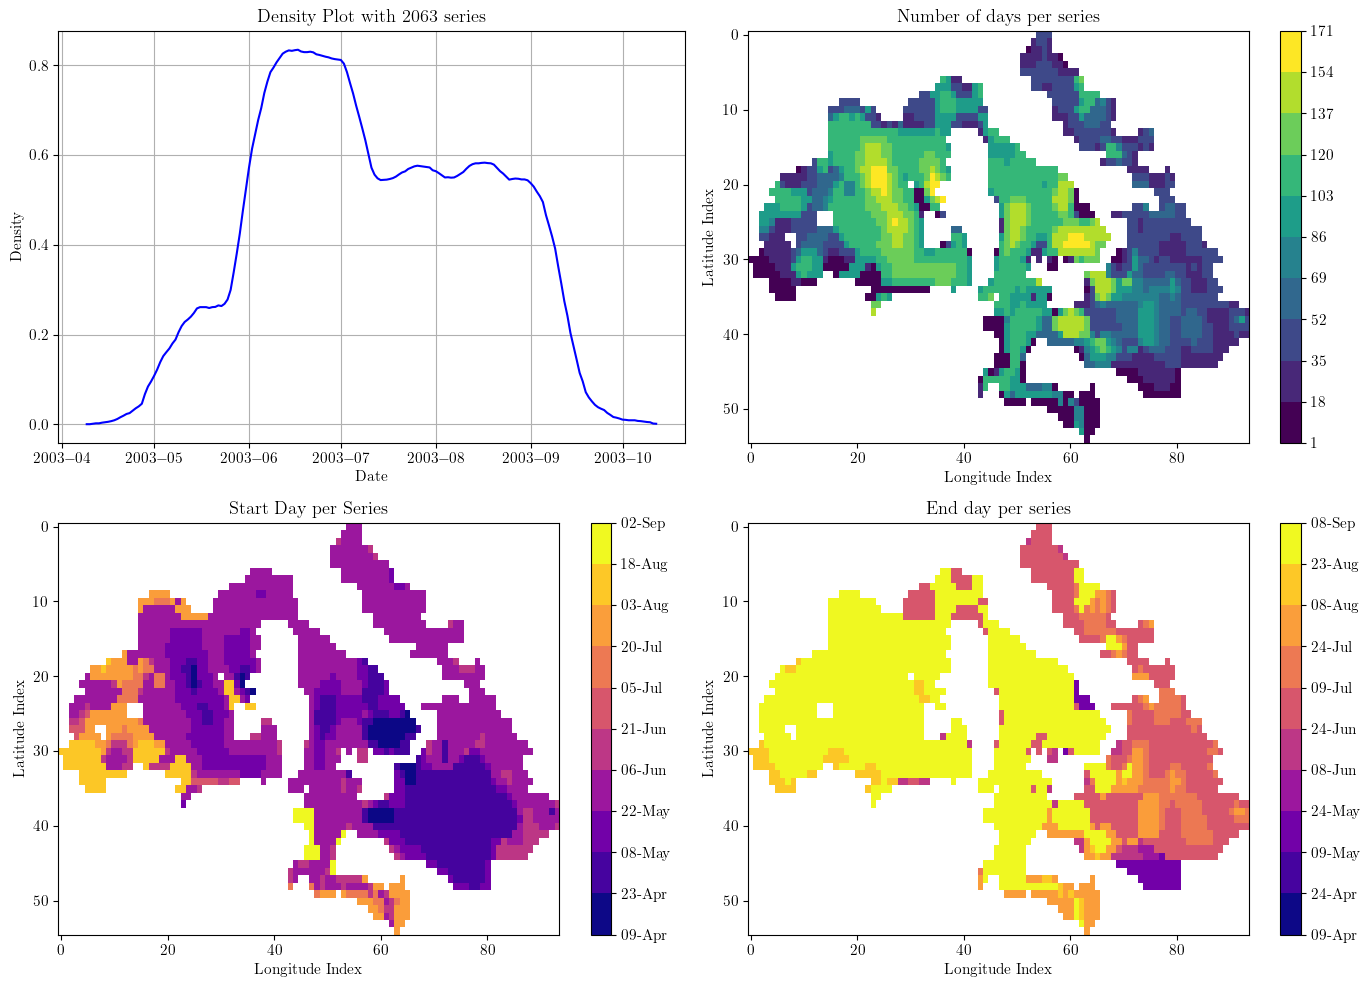

In [28]:
ccs.sort(key=len)
ccs.reverse()
for i, cc in enumerate(ccs[:2]):
    ub.show_connected_component(cc, n_year, ts_date, lat, lon, grid_burst, values, lon_min, lon_max, lat_min, lat_max)

In [29]:
if False:
    anim = ub.cc_time_travel(ccs[9], ts_date, grid_burst, lat, lon, values)
    HTML(anim.to_jshtml())
    FFwriter = animation.FFMpegWriter(fps=3)
    anim.save('connected_component_time_travel.mp4', writer = FFwriter)


## Time Travel

In [30]:
if False:
    plt.rcParams['animation.embed_limit'] = 2**128
    start = np.where(ts_date == "01-01-2010")[0][0]
    grid_count = np.zeros((len(ts_date)-start, lat,lon))
    grid_count[:] = np.nan
    for (i,j) in coords:
        grid_count[:, i,j] = 0
        
    for (i,j) in coords:
        for burst in grid_burst[i,j]:
            s,e,z = burst
            if e >= start:
                bend = e - start
                bstart = e - start
                grid_count[bstart:bend+1,i,j] = int(np.sign(z))
    
    grid_weekly_count = np.zeros((1+(len(ts_date)-start)//7, lat,lon))
    grid_weekly_count[:] = np.nan
    for (i,j) in coords:
        grid_weekly_count[:, i,j] = 0
    for i in range(grid_count.shape[1]):
        for j in range(grid_count.shape[2]):
            for w in range(grid_weekly_count.shape[0]):
                grid_weekly_count[w,i,j] = np.sign(np.add.reduce(grid_count[w*7:(w+1)*7,i,j]))
                
    fig, ax = plt.subplots(figsize=(20, 10))
    cmap = ListedColormap(['blue', 'white', 'red'])  # Colors for -1, 0, and 1
    norm = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], cmap.N)  
    cmap.set_bad(color="darkgrey")
    
    # Initialize the image plot
    img = ax.imshow(grid_weekly_count[0], cmap=cmap, norm=norm)
    plt.close()
    
    # Add text element for displaying the current date
    date_text = ax.text(0.02, 0.95, '', transform=ax.transAxes, fontsize=20, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.5))
    formatted_dates = [f'Date: {date.strftime("%Y-%m-%d")}' for date in ts_date[start:start + len(grid_weekly_count) * 7:7]]
    # Update function for animation
    def update(frame):
        img.set_array(grid_weekly_count[frame])
        date_text.set_text(formatted_dates[frame])
        return img, date_text
    
    # Create animation
    anim = FuncAnimation(fig, update, frames=len(grid_weekly_count), interval=200, blit=False, cache_frame_data=False)
    with open("myvideo_weekly.html", "w") as f:
        print(anim.to_jshtml(), file=f)

    FFwriter = animation.FFMpegWriter()
    anim.save('weekly_time_travel.mp4', writer = FFwriter)
    HTML(anim.to_jshtml())

In [31]:
%%capture output
if export:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        os.system('jupyter nbconvert --no-input --output ' + filename_html + ' --to html ' + "paper_grid.ipynb")

[NbConvertApp] Converting notebook paper_grid.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 24 image(s).
[NbConvertApp] Writing 2786595 bytes to example_grid.html
